## Diabetes Data Analysis 

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
from warnings import filterwarnings
filterwarnings('ignore')


In [2]:
### Reading Data set 
df = pd.read_csv(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Observations
* This is a Diabetes dataset used for binary classification i.e. whether a patient has diabetes or not
* here,
    * Pregnancies are the count of prengnancy ,
    * Glucose is the blood glucose level ,
    * BloodPressure is the Disistolic Blood Pressure,
    * Skin Thickness is measured by checking the thickness of the tricep fold
    * Insulin is the level of insulin present in the body
    * BMI is the Body mass Index
    * DiabetesPedigreeFunction	is the heriditory predisposition to Diabetes
    * Age is how old the person is
    * Outcome is the Binary value of whether a person has diabetes or not
* The dataset has medical values which can never be zero or negative since we see minimum using the describe function we can tell that the columns "Glucose", "BloodPressure" , "SkinThickness", "Insulin", "BMI" can never be zero
* There are no null values present in the dataset 

### Data Cleaning 

In [5]:
## removing the zeroes 
colms = [ "Glucose", "BloodPressure" , "SkinThickness", "Insulin", "BMI" ]

for colm in colms:
    print(colm,(df[colm] == 0).sum())

Glucose 5
BloodPressure 35
SkinThickness 227
Insulin 374
BMI 11


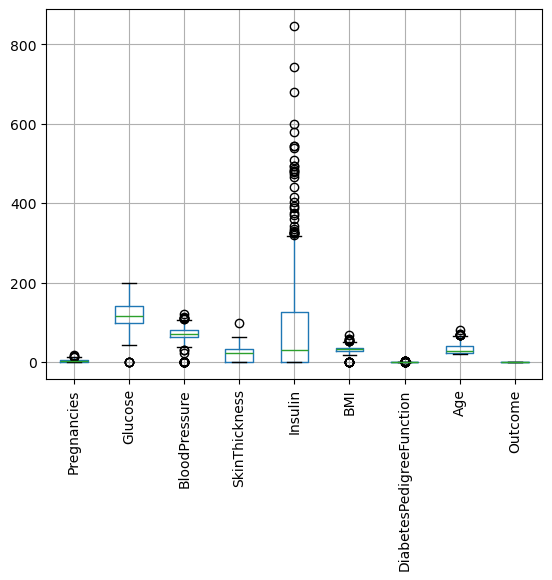

In [6]:
## checking for outliers to find if to replace by mean or median
df.boxplot()
plt.xticks(rotation = 90)
plt.show()

In [7]:
### Since every column has some outlier we are going to replace by median
df[colms] = df[colms].replace(0, np.nan)
        

In [8]:
for colm in colms:
    df[colm].fillna(df[colm].median(), inplace = True )

In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885,0.348958
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232,0.476951
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Observations
* Pregnancies: Most women had 1–6 pregnancies, with a slight tendency toward higher pregnancy counts.
* Glucose: Glucose levels vary considerably and are moderately right-skewed, making it a key diabetes indicator.  
* BloodPressure: Blood pressure is approximately normally distributed around 72 mmHg.
* SkinThickness: Skin thickness is centered around 29 with a few unusually high values indicating outliers.
* Insulin: Insulin is highly right-skewed with extreme outliers and the greatest variability among all features.
* BMI: The average BMI is in the obese range, suggesting obesity is common in the dataset.
* DiabetesPedigreeFunction: Most individuals have low hereditary risk scores, with a few having strong family histories of diabetes.
* Age: The dataset mainly contains younger adults, with a smaller number of older individuals creating a right-skewed distribution.
* Outcome: Approximately 35% of patients are diabetic and 65% are non-diabetic, indicating moderate class imbalance.

### Visualization

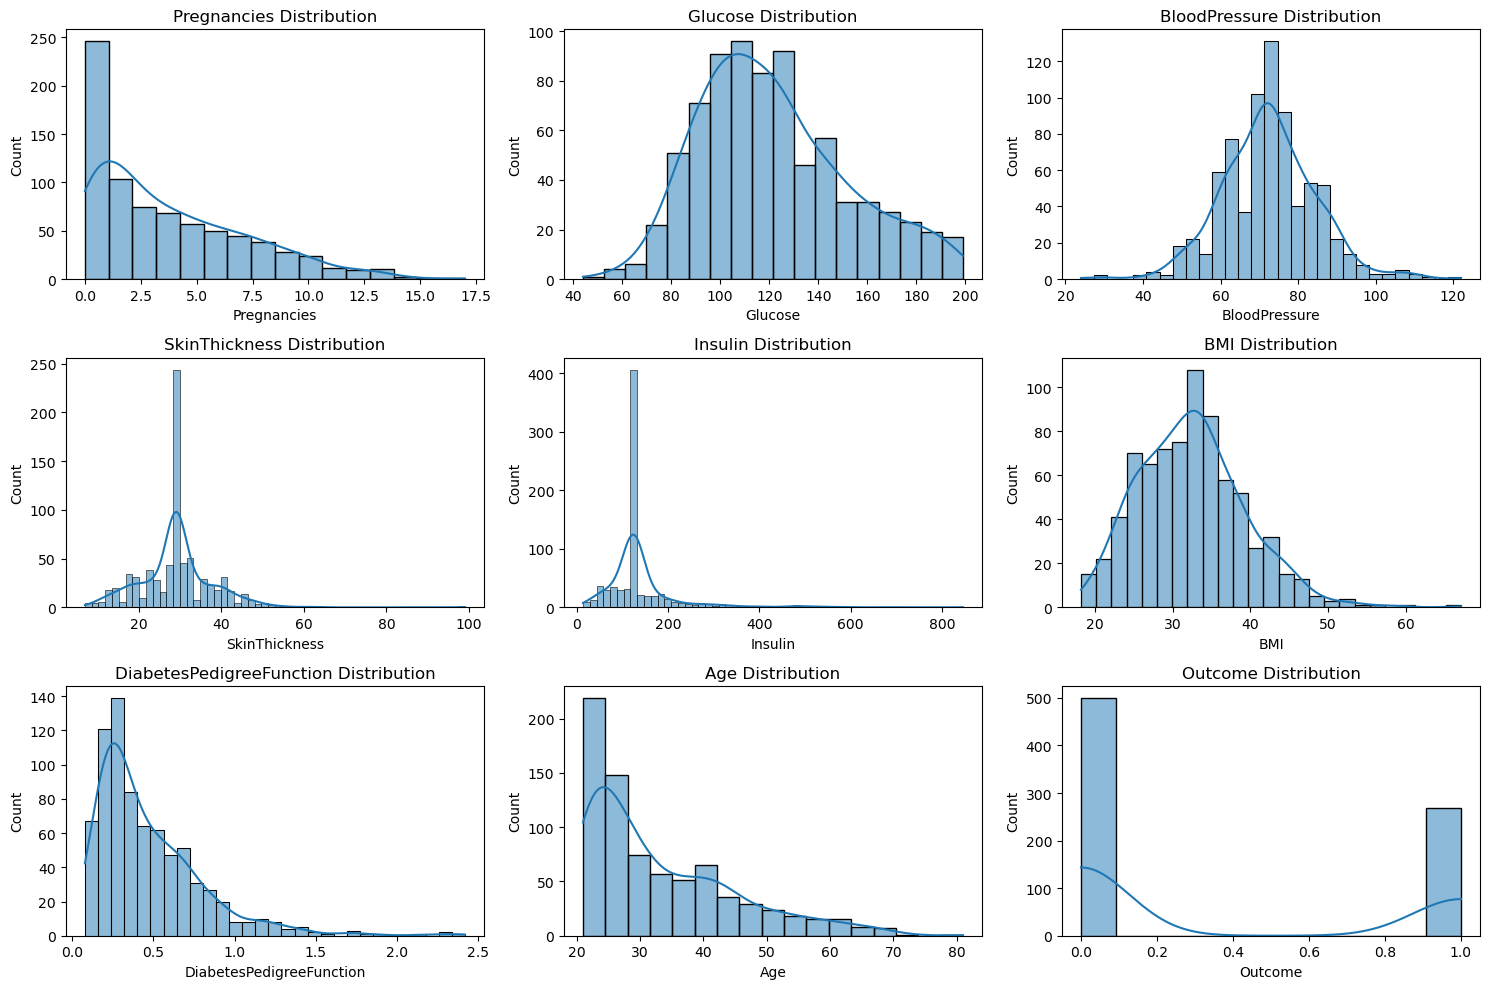

In [10]:
columns = ["Pregnancies","Glucose", "BloodPressure", "SkinThickness" , "Insulin" ,"BMI", "DiabetesPedigreeFunction","Age","Outcome"]
fig , axes = plt.subplots(3,3 , figsize = (15,10))
axes = axes.flatten()
for i, colm in enumerate(columns):
    sns.histplot(data  = df , x = colm , kde = True , ax = axes[i])
    axes[i].set_title(f"{colm} Distribution")
plt.tight_layout()
plt.show()
    

### Outcomes
* Pregnancies: Strongly right-skewed, with most women having few pregnancies and progressively fewer having higher counts.
* Glucose: Approximately bell-shaped with a slight right skew, indicating most glucose values are concentrated around 100–130.
* BloodPressure: Nearly normally distributed and centered around 70–75 mmHg with few extreme values.
* SkinThickness: Positively skewed with a noticeable concentration around 25–35 and a few high-value outliers.
* Insulin: Highly right-skewed with extreme outliers, indicating large variability and non-normality.
* BMI: Roughly bell-shaped with a slight right skew, showing most individuals have BMI values between 25 and 40.
* DiabetesPedigreeFunction: Strongly right-skewed, with most individuals having low genetic risk scores.
* Age: Right-skewed, indicating the dataset contains mostly younger adults with fewer older individuals.
* Outcome: Moderately imbalanced, with significantly more non-diabetic (0) than diabetic (1) cases.

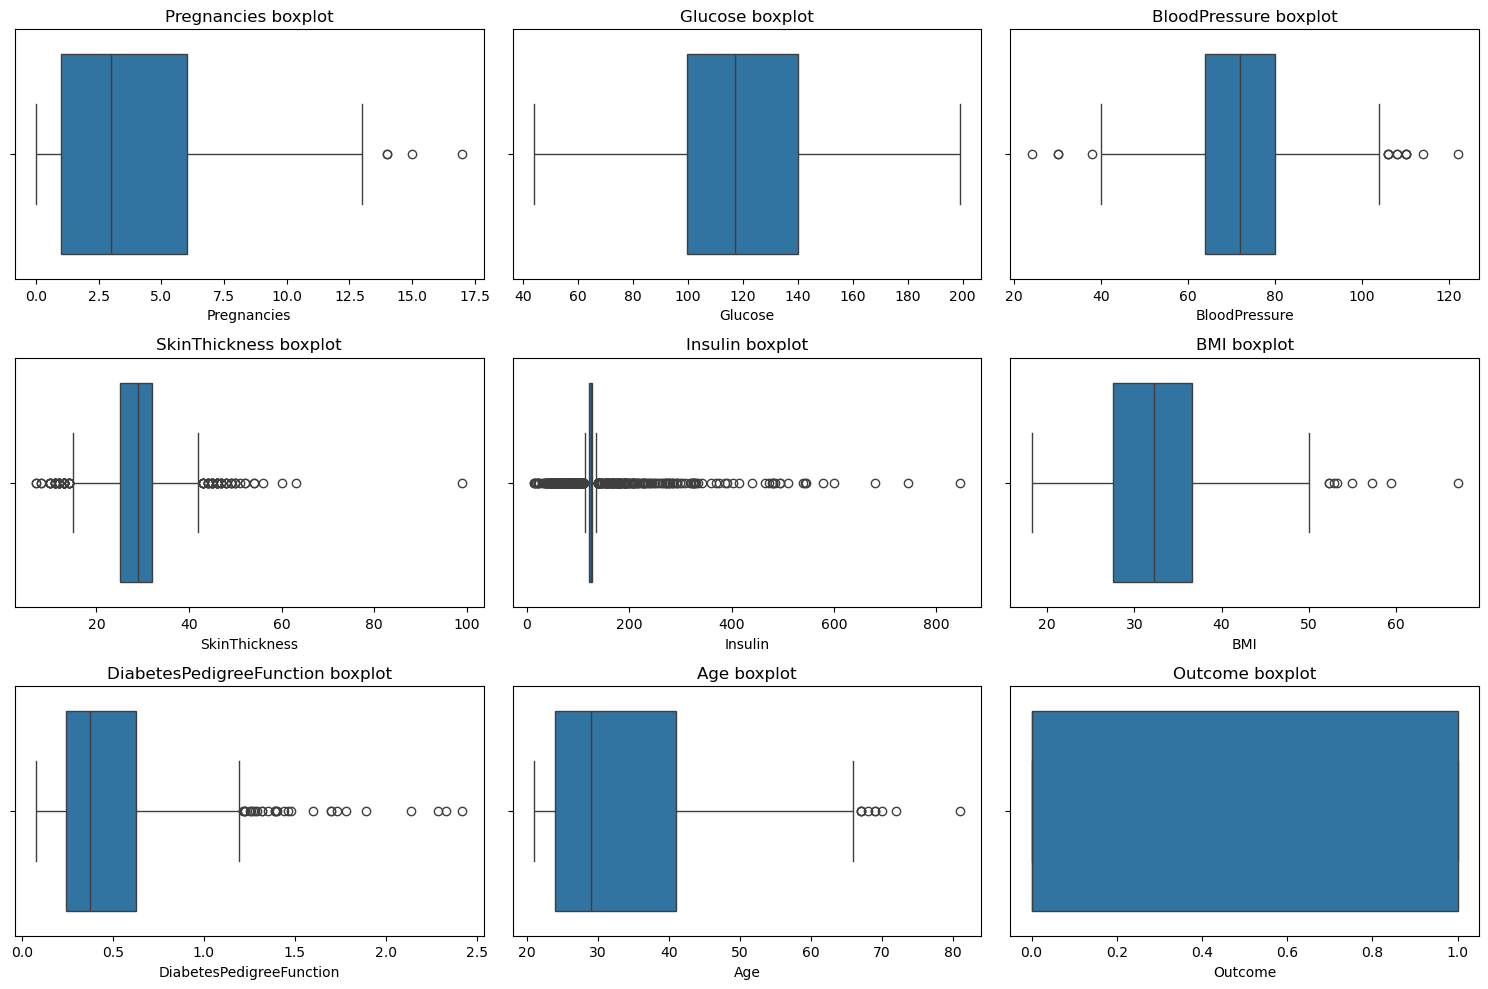

In [11]:
columns = ["Pregnancies","Glucose", "BloodPressure", "SkinThickness" , "Insulin" ,"BMI", "DiabetesPedigreeFunction","Age","Outcome"]
fig , axes = plt.subplots(3,3, figsize = (15,10))
axes = axes.flatten()

for i, colm in enumerate(columns):
    sns.boxplot(data = df , x = colm , ax = axes[i])
    axes[i].set_title(f"{colm} boxplot")
plt.tight_layout()
plt.show()

### Outcomes 
* Pregnancies: A few high-pregnancy cases (above ~13) appear as outliers, while most observations lie between 0 and 6.
* Glucose: The distribution is fairly balanced with no significant outliers, indicating stable glucose measurements.
* BloodPressure: A small number of unusually low and high blood pressure values are present as outliers.
* SkinThickness: Several outliers exist on both ends, with one extremely high value around 100.
* Insulin: Contains a very large number of extreme outliers, making it the most variable feature in the dataset.
* BMI: Most BMI values fall between 27 and 37, with a few high-value outliers above 50.
* DiabetesPedigreeFunction: Positively skewed with several high-value outliers indicating elevated hereditary diabetes risk.
* Age: Most individuals are below 45 years, with a few older-age outliers above 65 years.
* Outcome: Binary target variable (0 and 1), so outlier analysis is not meaningful for this feature.

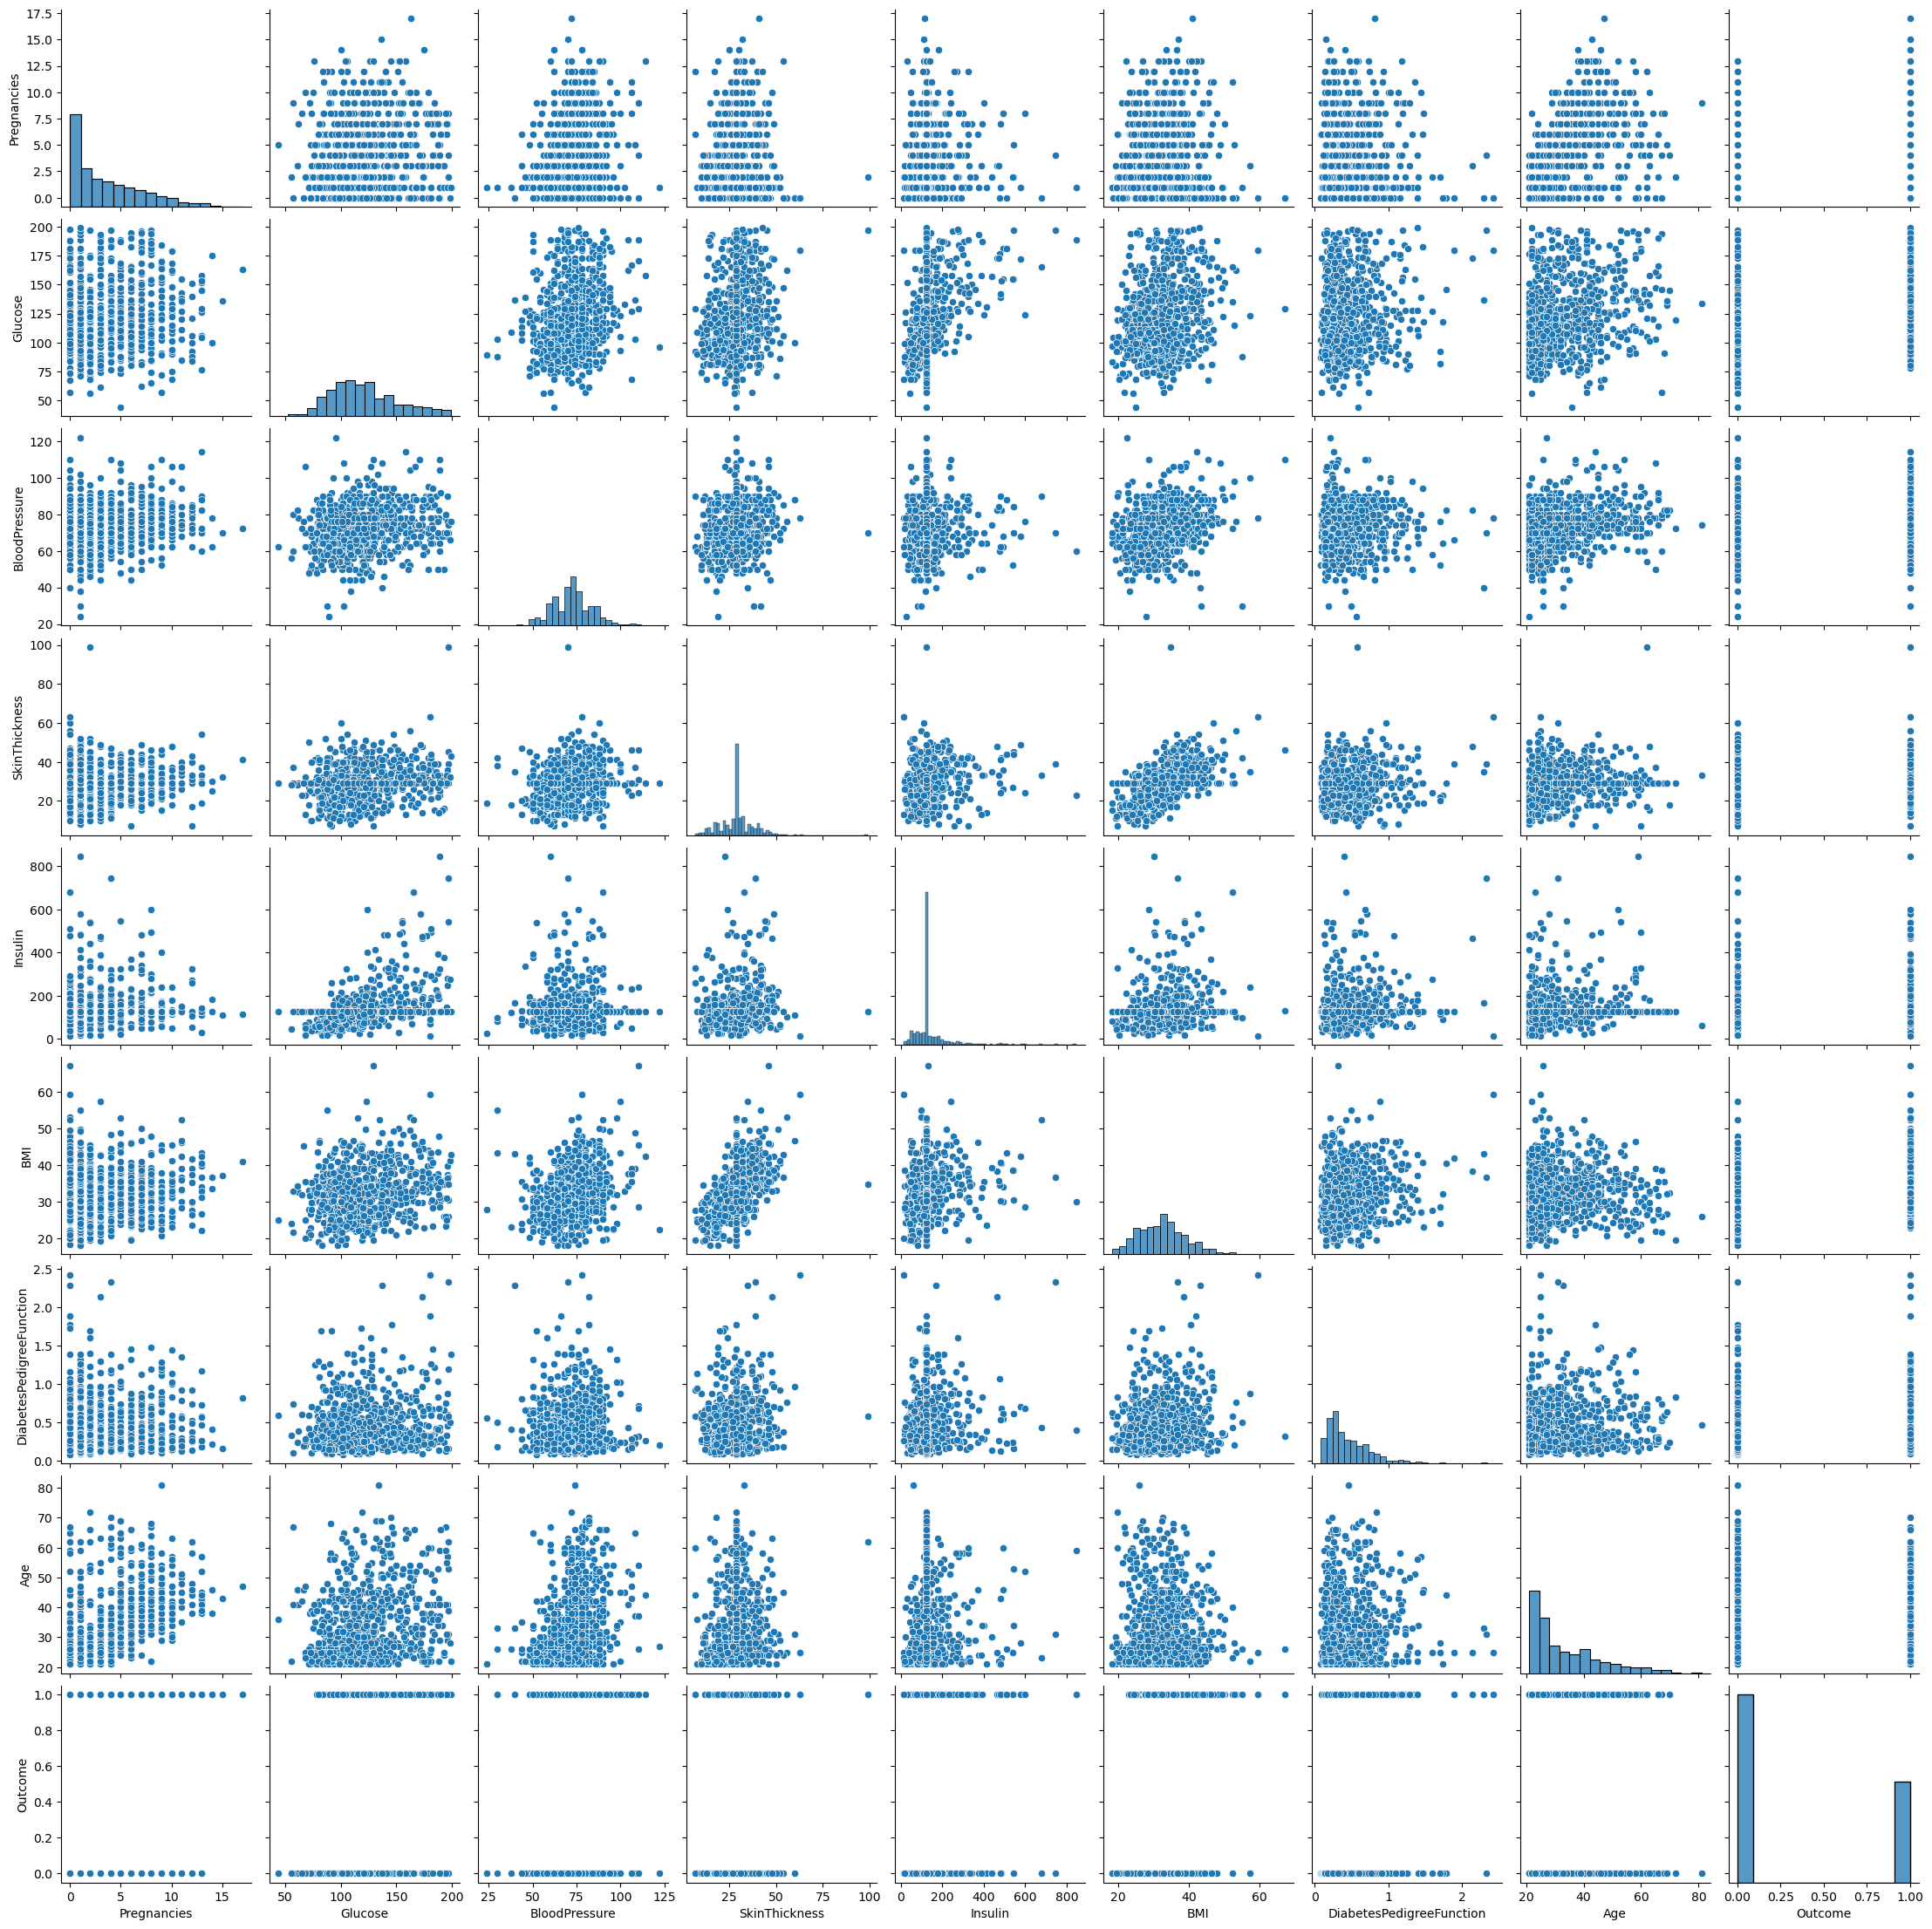

In [12]:
sns.pairplot(df)
plt.show()

In [13]:
df_corr = df.corr()
df_corr

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.128213,0.208615,0.081770,0.025047,0.021559,-0.033523,0.544341,0.221898
Glucose,0.128213,1.000000,0.218937,0.192615,0.419451,0.231049,0.137327,0.266909,0.492782
BloodPressure,0.208615,0.218937,1.000000,0.191892,0.045363,0.281257,-0.002378,0.324915,0.165723
SkinThickness,0.081770,0.192615,0.191892,1.000000,0.155610,0.543205,0.102188,0.126107,0.214873
Insulin,0.025047,0.419451,0.045363,0.155610,1.000000,0.180241,0.126503,0.097101,0.203790
BMI,0.021559,0.231049,0.281257,0.543205,0.180241,1.000000,0.153438,0.025597,0.312038
DiabetesPedigreeFunction,-0.033523,0.137327,-0.002378,0.102188,0.126503,0.153438,1.000000,0.033561,0.173844
Age,0.544341,0.266909,0.324915,0.126107,0.097101,0.025597,0.033561,1.000000,0.238356
Outcome,0.221898,0.492782,0.165723,0.214873,0.203790,0.312038,0.173844,0.238356,1.000000


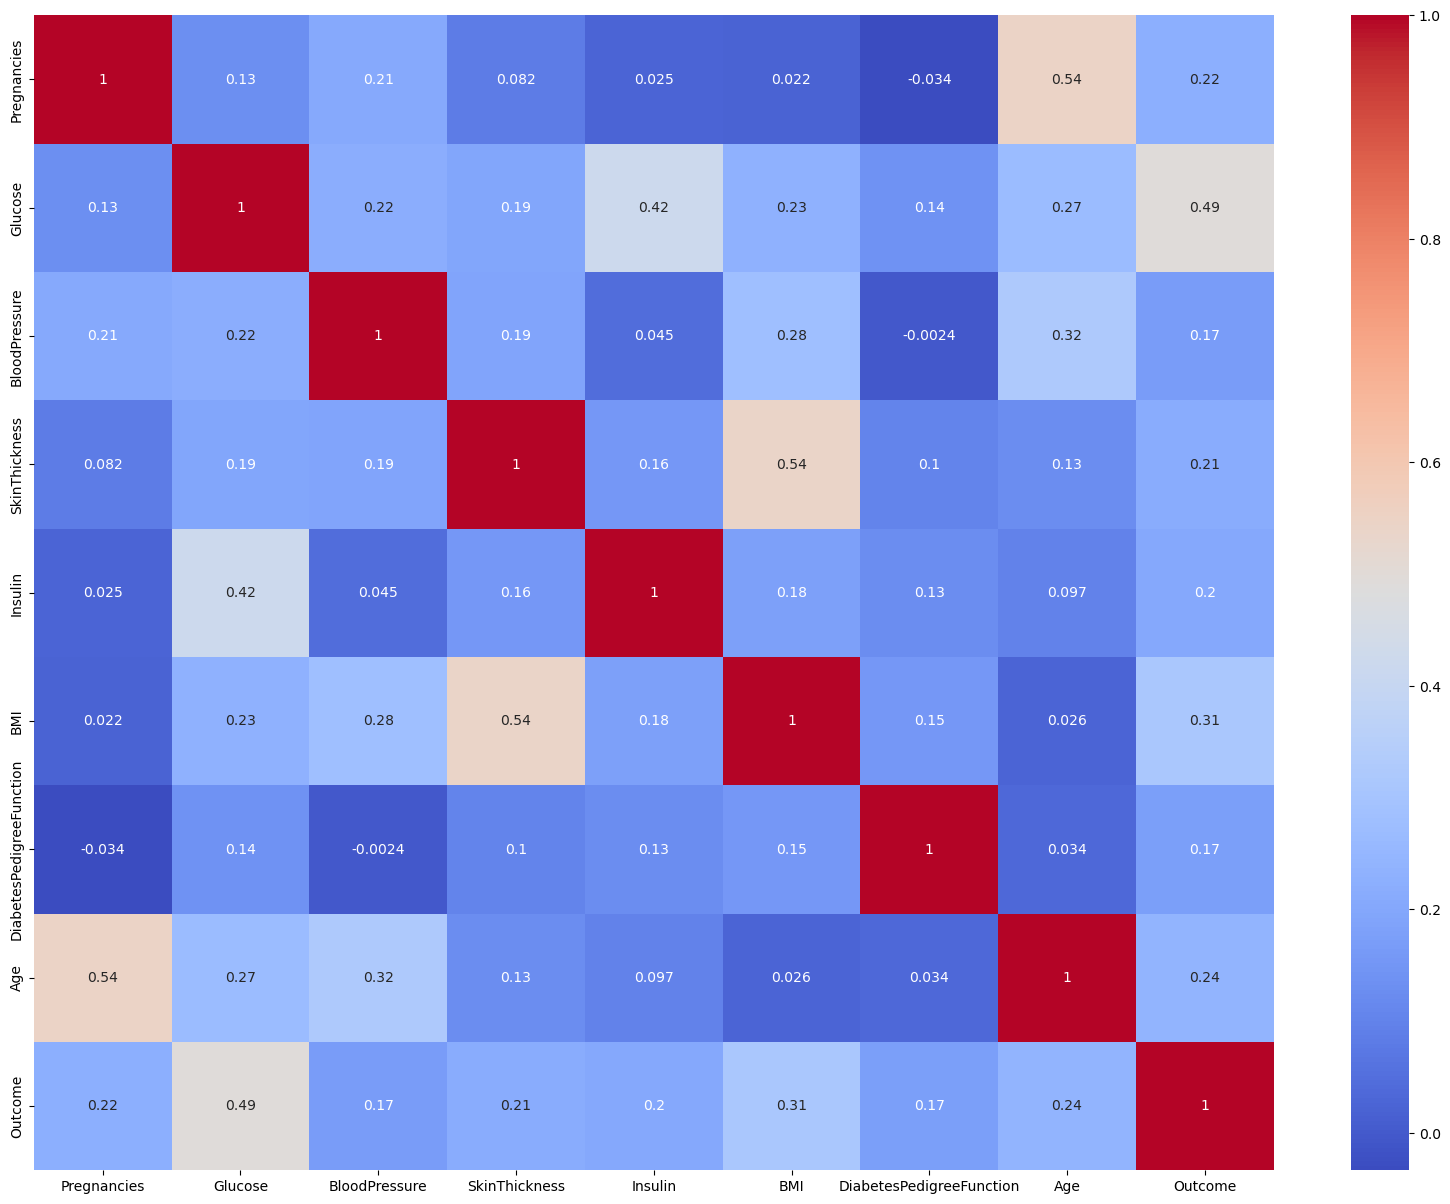

In [14]:
## Heat map 
plt.figure(figsize  = (20,15))
sns.heatmap(df.corr(numeric_only = True) , annot = True , cmap = "coolwarm")
plt.show()

### Outcome
* Glucose is the strongest predictor of diabetes.
* BMI and Age are the next most influential features.
* Pregnancies has a moderate indirect effect through Age.
* No pair of features has a correlation above 0.8, indicating no severe multicollinearity issues.
* SkinThickness and BMI (0.54) and Pregnancies and Age (0.54) are the strongest feature-to-feature relationships.

### Scaling 

In [17]:
X =df.drop('Outcome',axis = 1)
y = df['Outcome']

In [32]:
### building a test train split 80-20 split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

In [33]:
### Scaling each
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_train_scaled = pd.DataFrame(X_train_scaled , columns = X.columns)
X_test_scaled = scaler.fit_transform(X_test)
X_test_scaled = pd.DataFrame(X_test_scaled , columns = X.columns)
X_test_scaled

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.852530,1.164845,-0.828843,-0.044202,-0.248008,-0.719331,-0.465625,0.634010
1,1.690549,-1.669207,2.886305,-0.760745,-0.933414,0.425614,-0.492533,1.245336
2,-0.544168,0.012538,0.232628,-0.283050,0.428378,0.482155,0.099438,-0.588642
3,0.852530,-0.236609,-0.828843,-0.044202,-0.248008,-0.719331,0.843887,0.110016
4,-0.544168,-1.482347,-0.121196,-0.044202,-0.248008,-0.026710,-1.039658,-0.937972
...,...,...,...,...,...,...,...,...
149,-0.264828,-1.046339,-1.359579,-2.193830,-0.888321,-1.086845,-0.546349,-0.937972
150,-0.544168,-0.859478,0.232628,-1.357863,-0.780099,-0.125656,0.595738,-0.850639
151,-0.544168,-1.233199,-1.890314,-0.880168,-0.338193,-0.563845,3.734980,-0.675975
152,0.014511,1.943431,0.409539,1.150035,1.122802,0.637641,-0.555318,-0.151981


In [34]:
X_train_scaled

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769477,0.310794,-0.792169
1,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417498,-0.116439,0.561034
2,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359790,-0.764862,-0.707594
3,-0.851355,0.811525,-1.315932,-0.004766,-0.161437,-0.402832,0.262314,-0.369293
4,-1.153338,-0.889646,-0.663676,1.120776,-0.415565,1.782373,-0.337630,-0.961320
...,...,...,...,...,...,...,...,...
609,-0.549372,0.411249,-0.174484,-0.004766,-0.161437,-0.520158,0.195653,-0.876744
610,0.054593,-1.523416,-0.826740,-0.004766,-0.161437,0.227798,-0.261879,-0.707594
611,-0.851355,-0.822933,-0.174484,1.233330,-0.161437,0.829096,-0.786072,-0.284718
612,1.866489,-0.355945,-0.174484,-0.229874,-0.161437,-0.725480,-1.019383,0.561034


In [36]:
## Fitting the logistic regression model 
from sklearn.linear_model import LogisticRegression 
model = LogisticRegression(max_iter = 1000)
model.fit(X_train_scaled , y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [37]:
y_pred = model.predict(X_test_scaled) 

In [38]:
from sklearn.metrics import accuracy_score
print("Accuracy: ", accuracy_score(y_test,y_pred))

Accuracy:  0.7012987012987013


In [40]:
from sklearn.metrics import confusion_matrix , classification_report

cm = confusion_matrix(y_test, y_pred)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.59      0.48      0.53        54

    accuracy                           0.70       154
   macro avg       0.67      0.65      0.66       154
weighted avg       0.69      0.70      0.69       154



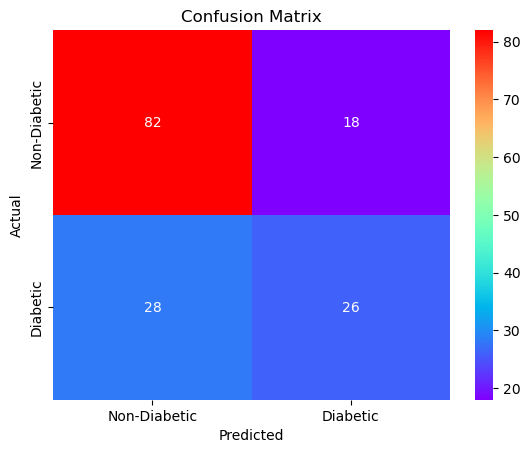

In [47]:
sns.heatmap(cm , annot =True, xticklabels=['Non-Diabetic', 'Diabetic'],yticklabels=['Non-Diabetic', 'Diabetic'], cmap = "rainbow" )
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

### Report
The Logistic Regression model correctly classified 82 non-diabetic and 26 diabetic patients, achieving an overall accuracy of 70.13%. The model demonstrated good specificity (82%) but a lower recall (48.1%), indicating that while it effectively identified non-diabetic patients, it missed a considerable number of diabetic cases.

In [49]:
## AUC - ROC curve 
from sklearn.metrics import roc_auc_score
y_prob = model.predict_proba(X_test_scaled)[:, 1]

auc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.8125925925925926


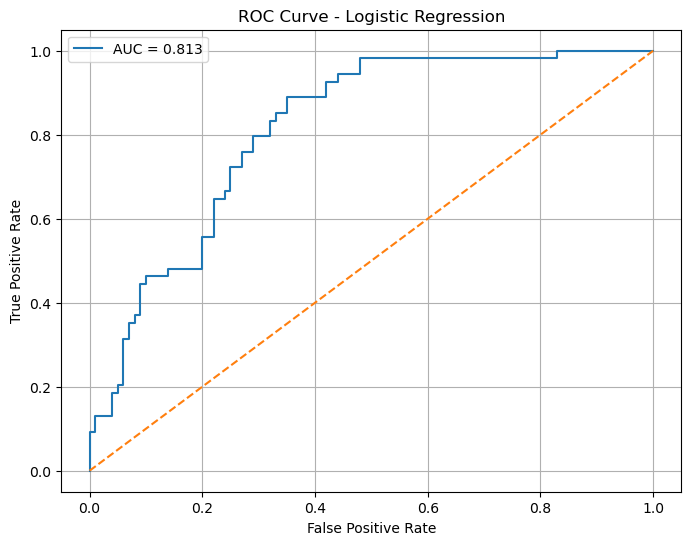

In [51]:
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'AUC = {auc:.3f}')
plt.plot([0, 1], [0, 1], linestyle='--')  # Random classifier

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()

### Conclusion
The ROC curve demonstrates the trade-off between sensitivity and specificity across different classification thresholds. The Logistic Regression model achieved an AUC score of 0.813, indicating very good discriminatory power and an 81.3% probability of correctly ranking a randomly selected diabetic patient higher than a randomly selected non-diabetic patient.

In [54]:
## Evaluating the model using coefficients 
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

print(coef_df.sort_values(by='Coefficient', ascending=False))

                    Feature  Coefficient
1                   Glucose     1.182511
5                       BMI     0.688735
0               Pregnancies     0.377502
6  DiabetesPedigreeFunction     0.233386
7                       Age     0.147798
3             SkinThickness     0.028225
2             BloodPressure    -0.044066
4                   Insulin    -0.066157


## a. Interpretation of the Logistic Regression Coefficients

| Feature | Coefficient | Interpretation |
|----------|----------:|-------------|
| Glucose | **1.1825** | Strongest positive effect; higher glucose levels significantly increase the probability of diabetes. |
| BMI | **0.6887** | Higher BMI substantially increases the likelihood of diabetes. |
| Pregnancies | **0.3775** | More pregnancies are associated with a higher diabetes risk. |
| DiabetesPedigreeFunction | **0.2334** | A stronger family history of diabetes increases the probability of being diabetic. |
| Age | **0.1478** | Older individuals have a slightly higher risk of diabetes. |
| SkinThickness | **0.0282** | Very weak positive effect on diabetes prediction. |
| BloodPressure | **-0.0441** | Negligible negative effect; not a strong predictor in this model. |
| Insulin | **-0.0662** | Slight negative effect after accounting for other variables, indicating limited predictive contribution. |

---

## b. Significance of Features in Predicting Diabetes

- **Glucose** is the most significant predictor, having the largest coefficient (**1.1825**), which aligns with medical knowledge that elevated blood glucose is a primary indicator of diabetes.
- **BMI** is the second most important feature (**0.6887**), showing that obesity is strongly associated with diabetes risk.
- **Pregnancies** (**0.3775**) and **DiabetesPedigreeFunction** (**0.2334**) also contribute meaningfully to prediction, indicating the importance of reproductive history and genetic predisposition.
- **Age** has a moderate positive impact, suggesting that diabetes risk increases with age.
- **SkinThickness**, **BloodPressure**, and **Insulin** have coefficients close to zero, implying they contribute relatively little to the model's predictions after considering the other features.

---

In [55]:
## Saving model using pickel so we wont have to train the model each time we open the app 
import pickle

pickle.dump(model, open('diabetes_model.pkl', 'wb'))
pickle.dump(scaler, open('scaler.pkl', 'wb'))